## Question:
## Whats the probability of pulling a red plus 2 card from a uno deck?

### Type of simulation:

#### The random process im simulating is drawing cards from a deck of 108 cards. one trial in my simulation is a drawing a card from the deck the outcome is different colors and different action cards. The compound event im measuring is having a red card and it be a plus two which is two events since theres two plus two cards 2 out of 108.

## Event:

## My question is asking P(RED and Plus+2) this is a joint probablity. 
### my question is asking for the joint probablity of red and plus 2.
### they aren't exclusive because both events can occur at the same time they can be red and be a plus 2.
### they aren't independent because they are dependent on each other since they fail the independent test 2/108 doesn't equal 25/108 times 8/108 these numbers are completely different.   

## Analysis:

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
rng = np.random.default_rng() 

In [4]:
colors = ['Red', 'Blue', 'Green', 'Yellow']
action_types = ['Skip', 'Reverse', 'Plus 2']
#containers
deck = []

In [5]:
# 1. Add zero cards (1 per color)
for color in colors:
    deck.append({'color': color, 'card_type': '0'})

In [6]:
for color in colors:
    for num in range(1, 10):
        deck.append({'color': color, 'card_type': str(num)})
        deck.append({'color': color, 'card_type': str(num)})

In [7]:
for color in colors:
    for action in action_types:
        deck.append({'color': color, 'card_type': action})
        deck.append({'color': color, 'card_type': action})

In [8]:
for _ in range(4):
    deck.append({'color': 'Wild', 'card_type': 'Wild'})
    deck.append({'color': 'Wild', 'card_type': 'Wild Draw 4'})

In [9]:
uno_deck_df = pd.DataFrame(deck)
uno_deck_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 108 entries, 0 to 107
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   color      108 non-null    str  
 1   card_type  108 non-null    str  
dtypes: str(2)
memory usage: 2.6 KB


In [10]:
# Set simulation parameters
num_trials = 100_000

In [11]:
# Perform random draws with replacement using numpy
draw_indices = rng.integers(low=0, high=len(uno_deck_df), size=num_trials)
simulated_draws = uno_deck_df.iloc[draw_indices].reset_index(drop=True)

In [12]:
simulated_draws['is_red_plus_two'] = (simulated_draws['color'] == 'Red') & (simulated_draws['card_type'] == 'Plus 2')

In [13]:
empirical_prob = simulated_draws['is_red_plus_two'].mean()
theoretical_prob = 2 / 108

In [14]:
print(f"Empirical Joint Probability: {empirical_prob:.5f} ({empirical_prob * 100:.3f}%)")
print(f"Theoretical Joint Probability: {theoretical_prob:.5f} ({theoretical_prob * 100:.3f}%)")

Empirical Joint Probability: 0.01863 (1.863%)
Theoretical Joint Probability: 0.01852 (1.852%)


In [15]:
simulated_draws['trial_number'] = np.arange(1, num_trials + 1)
simulated_draws['running_prob'] = simulated_draws['is_red_plus_two'].cumsum() / simulated_draws['trial_number']

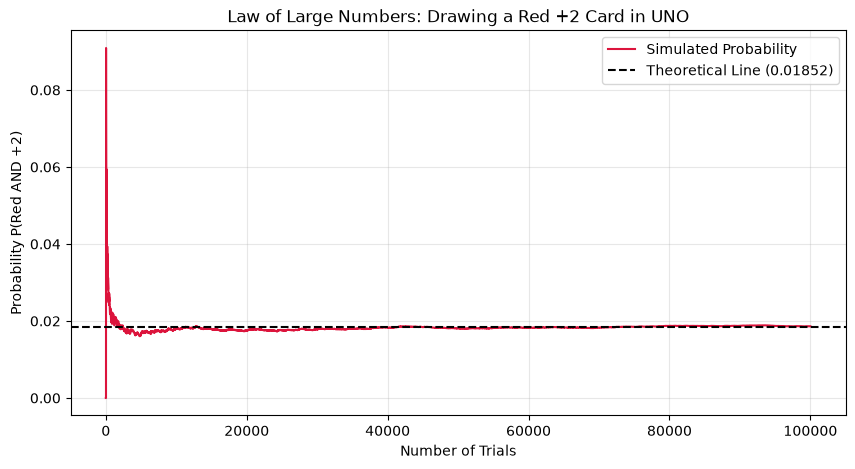

In [16]:
plt.figure(figsize=(10, 5))
plt.plot(simulated_draws['trial_number'], simulated_draws['running_prob'], color='crimson', label='Simulated Probability')
plt.axhline(y=theoretical_prob, color='black', linestyle='--', label=f'Theoretical Line ({theoretical_prob:.5f})')

plt.title('Law of Large Numbers: Drawing a Red +2 Card in UNO')
plt.xlabel('Number of Trials')
plt.ylabel('Probability P(Red AND +2)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

In [17]:
sample_trials = np.linspace(1000, num_trials, 10, dtype=int)
desmos_data = simulated_draws.loc[simulated_draws['trial_number'].isin(sample_trials), ['trial_number', 'running_prob']]

# Print in tab-separated format for direct copy-paste into Desmos
print("Copy the two columns below and paste directly into a Desmos table (Ctrl+V):")
print("x_1\ty_1")
for _, row in desmos_data.iterrows():
    print(f"{int(row['trial_number'])}\t{row['running_prob']:.5f}")

Copy the two columns below and paste directly into a Desmos table (Ctrl+V):
x_1	y_1
1000	0.02100
12000	0.01808
23000	0.01757
34000	0.01785
45000	0.01840
56000	0.01829
67000	0.01828
78000	0.01858
89000	0.01872
100000	0.01863


## Conclusion:

### To answer whats the joint probablity of the card im pulling to be red plus 2 card lets found out our Theoretical joint probablity our standard uno deck is 108 cards and theres only two red plus two in a deck so the amount of red plus two cards divided by our total deck size to get the probablity of pulling such a card when you first draw from the deck is 2/108 or 01852 to put it more simply 1.852% but what about our simulations? my code above as you can see runs over 100000 times thats crazy right? but taking all that data and finding the mean of it gives us our Empirical Joint Probability which is .01863 or 1.863% and as you can our percents are pretty close to eachother and these mean more in the graph above as you can see our theoricl is just a line its what were predicting it to be. Then as you can see our data goes pretty wild at the beginning but overtime as simulations data tries to even out with our theortical data this means our calculation of our theoretical is doing great since the data above shows as its getting closer to the line and eventually over time the 1.863% will become 1.852% proving theoretical correct. this shows how my graph supports that the joint probablity of pulling a red plus card which is 1.852%.